In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import sys

In [3]:
sys.path.append("../scripts")
from tools import read_sm_file, add_risk_parameters, compute_topological_indicators, visualize_dag, compute_times, draw_random_durations, beta_pert_sample, evaluate_at_EV, simulation

In [4]:
sns.set_theme(palette='tab10',style='whitegrid',font='sans-serif')

## PSPLIB dataset

A classical benchmark for RCPSP problems

Kolisch, R., & Sprecher, A. (1997). PSPLIB-a project scheduling problem library: OR software-ORSEP operations research software exchange program. European journal of operational research, 96(1), 205-216.

We have sampled 100 problems for each subset {J120, J90, J60, J30}

In [6]:
# Metadata
psplib_metadata = pd.read_csv('../PSPLIB_sample/psplib_sample_metadata.csv')

**Network Topology parameters** Vanhoucke (2008):
- CNC   Coefficient of Network Complexity
- OS    Order Strength
- #Act	Number of activities	
- SP	Serial-Parallel Network Indicator	
- AD	Activity distribution Indicator	
- LA	Length arcs indicator	
- I5	I5 indicator	
- TF	Total float indicator	

According to Vanhoucke, **SP** is central because it captures the project network’s degree of seriality versus parallelism, and that directly affects how much of the network is critical.

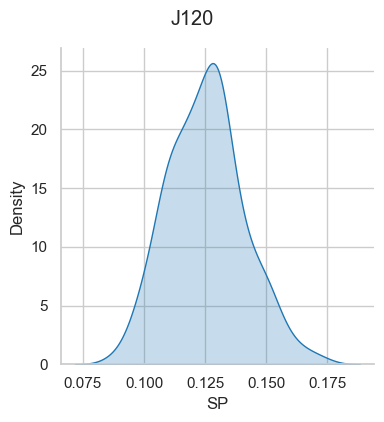

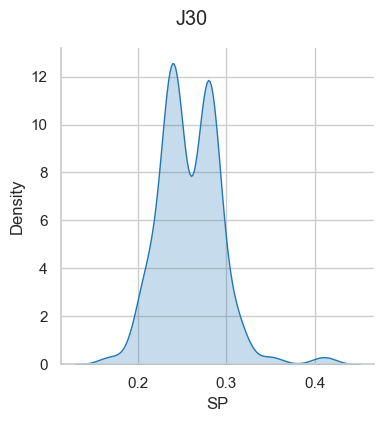

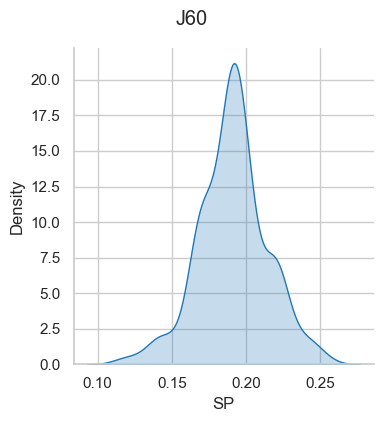

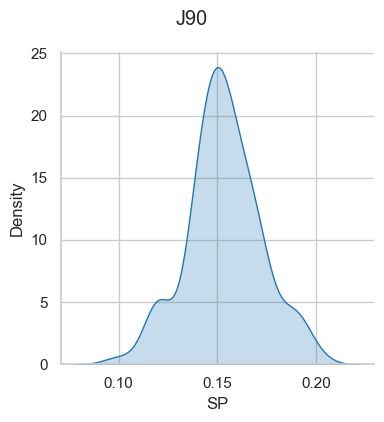

In [8]:
for s in psplib_metadata['SubSet'].unique():
    g=sns.displot(psplib_metadata[psplib_metadata['SubSet'] == s], x='SP', kind='kde',
                fill=True, height=4, aspect=1, common_norm=False)
    g.fig.suptitle(f'{s}', y=1.05)  

## Checking topology for one project

In [12]:
# Project ID for the current analysis
project_id = psplib_metadata.sample(n=1).index[0]  # Example: take the first project ID from the metadata
psplib_metadata.loc[project_id,'FileName']

'j3038_1.sm'

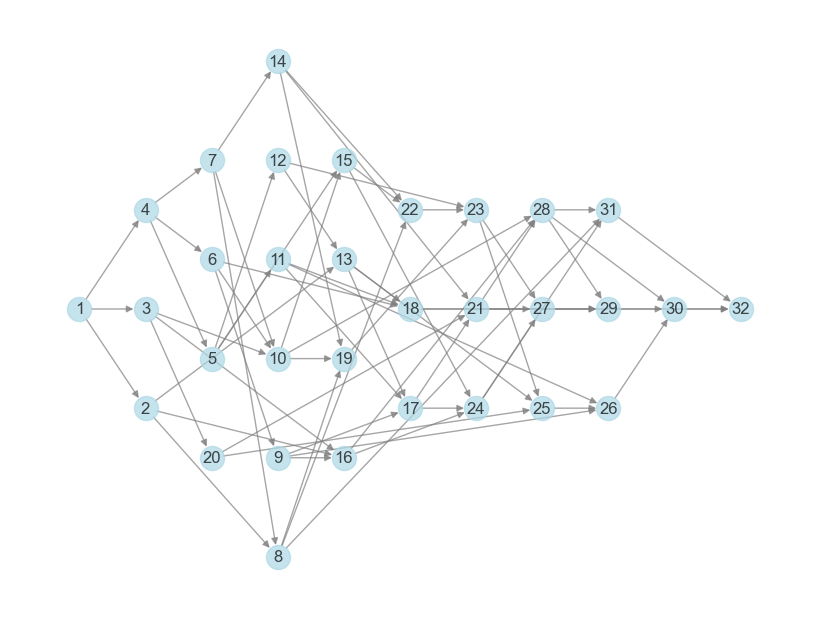

In [13]:
# Create a directed acyclic graph (DAG) from the project file
G=read_sm_file(f'../PSPLIB_sample/{psplib_metadata.loc[project_id,"FileName"]}')
visualize_dag(G)

In [14]:
topological_index=['#Act','CNC', 'OS','SP','AD','LA','I5','TF']

In [20]:
# Check topological indices
for (z, value) in zip(topological_index,compute_topological_indicators(G)):
    print(f"{z}: {psplib_metadata.loc[project_id,z]} vs {value:0.4f}")


#Act: 30 vs 30.0000
CNC: 2.07 vs 2.0667
OS: 0.57 vs 0.5747
SP: 0.28 vs 0.2759
AD: 0.21 vs 0.2143
LA: 0.08 vs 0.0800
I5: 0.77 vs 0.7714
TF: 0.17 vs 0.1726
